# 14. 준지도 학습 실험 — 가짜 라벨을 더하면 실제로 좋아지나

- fold마다: 라벨로 학습 → unlabeled reference(9~10월)에 가짜 라벨 → 라벨+가짜 라벨로 재학습 → **진짜 라벨로만 평가**
- 테스트 Run은 가짜 라벨 생성·재학습 어디에도 안 들어감
- S0 라벨만 / S1 +가짜 정상 / S2 +가짜 정상·불량 / S3 +가짜 정상·불량(물리 규칙 상위 1%만)
- 변수: 13번 물리 변수(sup_phys, 인과적 dev_*)

In [1]:
%load_ext autoreload
%autoreload 2
import os
import pandas as pd
from run_compare import load_product
from model_phys import add_phys
from model_v2 import evaluate_v2, f1_v2
from semi_phys import run_semi, pseudo_diagnostics, err_fact_table, plot_semi_compare, VARIANTS
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
OUT = './outputs/semi'
os.makedirs(OUT, exist_ok=True)
PRODUCTS = ['cn7', 'rg3']
REF_TAG = '2020-09-01_2020-11-30'          # 13번에서 만든 reference 캐시
FEAT, REF = {}, {}
for p in PRODUCTS:
    FEAT[p] = add_phys(load_product(p)[0])
    REF[p] = add_phys(pd.read_csv(f'./base/ref_{p}_features_{REF_TAG}.csv', parse_dates=['TimeStamp']))
    print(p, 'labeled', FEAT[p].shape, '| reference', REF[p].shape)

# 실험 설정 (결과 보기 전에 고정)
Q_POS, Q_NEG, W_PSEUDO, N_ITER = 0.995, 0.5, 0.3, 1

[cn7] 샷 1974, 불량 15
cn7 labeled (1974, 103) | reference (16353, 75)
[rg3] 샷 627, 불량 32
rg3 labeled (627, 103) | reference (4406, 75)


## 1. 실행 (logit, 원하면 MODELS에 'rf' 추가 — 시간 더 걸림)

In [2]:
MODELS = ['logit']
OOF, STATS = [], []
for mdl in MODELS:
    o, s = run_semi(FEAT, REF, model=mdl, q_pos=Q_POS, q_neg=Q_NEG, w_pseudo=W_PSEUDO, n_iter=N_ITER)
    OOF.append(o); STATS.append(s)
OOF, STATS = pd.concat(OOF, ignore_index=True), pd.concat(STATS, ignore_index=True)
OOF.to_csv(f'{OUT}/oof.csv', index=False, encoding='utf-8-sig')
STATS.to_csv(f'{OUT}/pseudo_stats.csv', index=False, encoding='utf-8-sig')
display(STATS.groupby(['variant', 'model'])[['학습 진짜 불량', '가짜 불량', '가짜 정상']].mean().round(1))

  cn7_R1 완료
  cn7_R2 완료
  cn7_R3 완료
  cn7_R4 완료
  cn7_R5 완료
  cn7_R6 완료
  rg3_R1 완료
  rg3_R2 완료
  rg3_R3 완료
  rg3_R4 완료
  rg3_R5 완료
  rg3_R6 완료


,,학습 진짜 불량,가짜 불량,가짜 정상
variant,model,,,
S0_라벨만,logit,43.1,0.0,0.0
S1_+가짜정상,logit,43.1,0.0,7203.0
S2_+가짜정상·불량,logit,43.1,105.0,7203.0
S3_+가짜정상·불량(물리),logit,43.1,57.8,7203.0


## 2. 비교 (진짜 라벨로만 평가)

,product,method,n_def,AP,AP_lo,AP_hi,AP/base,hit@5%,hit@10%,AP_가스,hit10_가스,AP_미성형,hit10_미성형
0,cn7,S0_라벨만|logit,15,0.024,0.014,0.090,3.215,3/15,3/15,0.011,0/11,0.042,3/4
1,cn7,S1_+가짜정상|logit,15,0.019,0.016,0.028,2.562,0/15,0/15,0.015,0/11,0.007,0/4
2,cn7,S2_+가짜정상·불량|logit,15,0.014,0.012,0.020,1.853,1/15,3/15,0.010,0/11,0.007,3/4
3,cn7,S3_+가짜정상·불량(물리)|logit,15,0.014,0.012,0.018,1.786,0/15,1/15,0.010,0/11,0.005,1/4
7,rg3,S3_+가짜정상·불량(물리)|logit,32,0.095,0.063,0.187,1.859,3/32,5/32,0.074,4/22,0.037,1/10
6,rg3,S2_+가짜정상·불량|logit,32,0.088,0.063,0.157,1.731,3/32,5/32,0.068,4/22,0.032,1/10
5,rg3,S1_+가짜정상|logit,32,0.066,0.053,0.109,1.290,3/32,4/32,0.052,3/22,0.021,1/10
4,rg3,S0_라벨만|logit,32,0.060,0.049,0.092,1.176,3/32,4/32,0.045,3/22,0.021,1/10


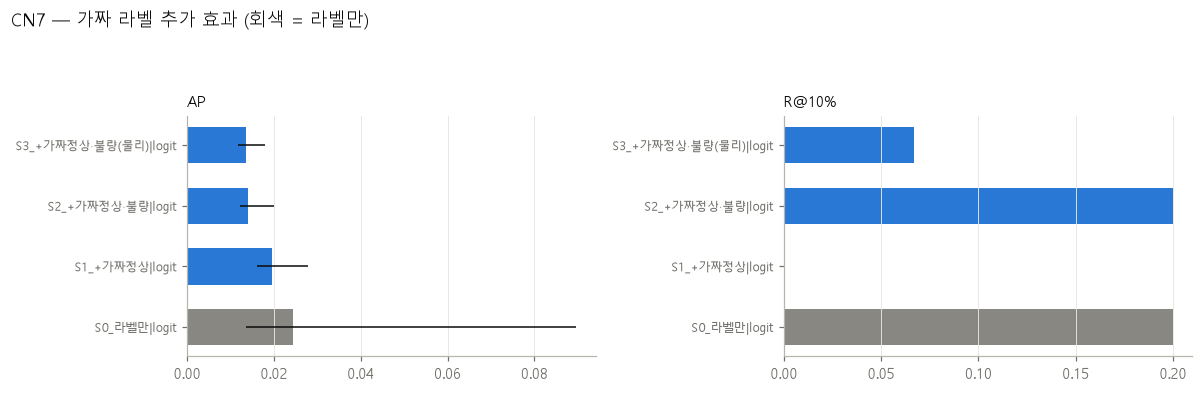

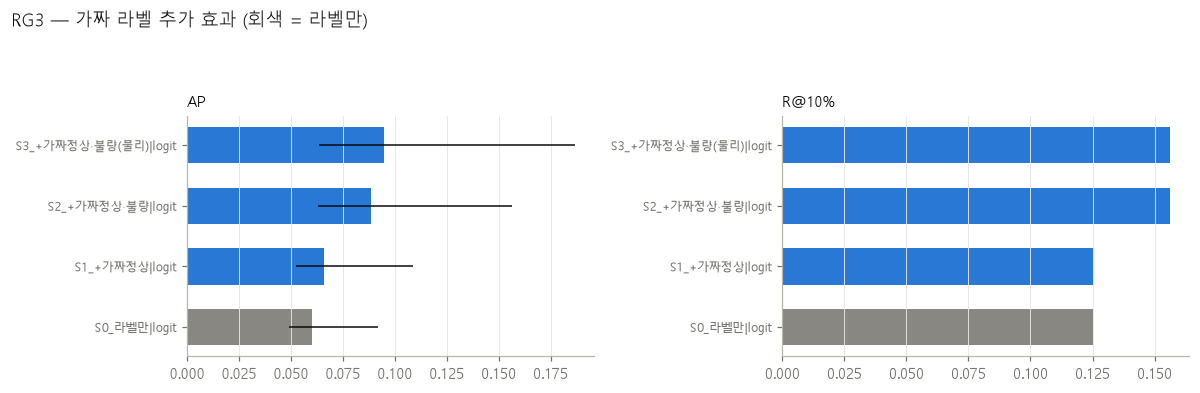

,product,method,임계값,F1,Precision,Recall,TP,FP,FN,선택 q
0,cn7,S0_라벨만|logit,pct≥0.99,0.051,0.029,0.200,3,99,12,NaN
1,cn7,S0_라벨만|logit,pct≥0.995,0.071,0.049,0.133,2,39,13,NaN
2,cn7,S0_라벨만|logit,pct≥0.999,0.000,0.000,0.000,0,3,15,NaN
4,cn7,S1_+가짜정상|logit,pct≥0.99,0.000,0.000,0.000,0,132,15,NaN
5,cn7,S1_+가짜정상|logit,pct≥0.995,0.000,0.000,0.000,0,66,15,NaN
6,cn7,S1_+가짜정상|logit,pct≥0.999,0.000,0.000,0.000,0,3,15,NaN
8,cn7,S2_+가짜정상·불량|logit,pct≥0.99,0.012,0.007,0.067,1,149,14,NaN
9,cn7,S2_+가짜정상·불량|logit,pct≥0.995,0.025,0.016,0.067,1,63,14,NaN
10,cn7,S2_+가짜정상·불량|logit,pct≥0.999,0.000,0.000,0.000,0,3,15,NaN
12,cn7,S3_+가짜정상·불량(물리)|logit,pct≥0.99,0.012,0.007,0.067,1,146,14,NaN


In [3]:
SUM = evaluate_v2(OOF)
SUM.to_csv(f'{OUT}/summary.csv', index=False, encoding='utf-8-sig')
cols = ['product', 'method', 'n_def', 'AP', 'AP_lo', 'AP_hi', 'AP/base', 'hit@5%', 'hit@10%',
        'AP_가스', 'hit10_가스', 'AP_미성형', 'hit10_미성형']
display(SUM[[c for c in cols if c in SUM]].round(3))
for p in PRODUCTS:
    plot_semi_compare(SUM.sort_values('method'), p, save=f'{OUT}/compare_{p}.png')
F1, _ = f1_v2(OOF)
F1.to_csv(f'{OUT}/f1.csv', index=False, encoding='utf-8-sig')
display(F1[F1['임계값'] != 'LORO 선택'].round(3))

## 3. 가짜 불량은 그럴듯한가 (전체 labeled로 학습한 모델 기준, 진단용)
가짜 불량의 물리 지표(재료부족·쿠션부족·계량지연)가 진짜 미성형과 비슷하면 그럴듯, reference 전체와 비슷하면 노이즈

In [4]:
MARKED, CMP = pseudo_diagnostics(FEAT, REF, q_pos=Q_POS)
display(CMP.round(3))

,제품,그룹,n,phys_shortfall,phys_cushion_low,phys_metering
0,cn7,reference 전체,16353,0.000,0.000,0.000
1,cn7,가짜 불량,82,0.367,0.000,13.768
2,cn7,진짜 정상,1959,0.000,0.000,0.000
3,cn7,진짜 가스,11,-0.058,0.000,0.337
4,cn7,진짜 미성형계열,4,15.626,0.995,0.169
5,rg3,reference 전체,4406,0.000,0.000,0.000
6,rg3,가짜 불량,23,0.000,0.000,2.248
7,rg3,진짜 정상,595,0.000,0.000,0.000
8,rg3,진짜 가스,22,0.083,0.000,0.067
9,rg3,진짜 미성형계열,10,0.112,0.000,1.068


## 4. 날짜별 가짜 불량 수 vs ERR_FACT_QTY (먼저 컬럼 의미 확인)

In [5]:
for p in PRODUCTS:
    t = err_fact_table(f'./linked/linked_unlabeled_{p}.csv', MARKED[p])
    t.to_csv(f'{OUT}/err_fact_{p}.csv', index=False, encoding='utf-8-sig')
    print(f'[{p}]  ERR_FACT_QTY 고유값 수가 날짜마다 1이면 → 날짜(계획) 단위 값'); display(t)
    if t['ERR_FACT_QTY 고유값 수'].max() == 1 and len(t) > 2:
        print('Spearman(가짜 불량 수, ERR_FACT_QTY):',
              round(t[['가짜 불량', 'ERR_FACT_QTY 최대']].corr(method='spearman').iloc[0, 1], 3))

[cn7]  ERR_FACT_QTY 고유값 수가 날짜마다 1이면 → 날짜(계획) 단위 값


,PART_FACT_PLAN_DATE,샷,가짜 불량,ERR_FACT_QTY 고유값 수,ERR_FACT_QTY 최소,ERR_FACT_QTY 최대,가짜 불량률
0,2020-09-02 오전 12:00:00,373,1,1,14,14,0.002681
1,2020-09-04 오전 12:00:00,1515,2,1,9,9,0.001320
2,2020-09-07 오전 12:00:00,712,2,1,6,6,0.002809
3,2020-09-19 오전 12:00:00,388,6,2,2,8,0.015464
4,2020-09-21 오전 12:00:00,2061,28,1,130,130,0.013586
5,2020-09-23 오전 12:00:00,3692,31,1,13,13,0.008397
6,2020-10-06 오전 12:00:00,1250,0,1,0,0,0.000000
7,2020-10-15 오전 12:00:00,2643,7,2,10,16,0.002649
8,2020-10-16 오전 12:00:00,875,3,1,5,5,0.003429
9,2020-10-17 오전 12:00:00,49,0,1,22,22,0.000000


[rg3]  ERR_FACT_QTY 고유값 수가 날짜마다 1이면 → 날짜(계획) 단위 값


,PART_FACT_PLAN_DATE,샷,가짜 불량,ERR_FACT_QTY 고유값 수,ERR_FACT_QTY 최소,ERR_FACT_QTY 최대,가짜 불량률
0,2020-09-15 오전 12:00:00,143,12,1,67,67,0.083916
1,2020-10-07 오전 12:00:00,1386,0,1,0,0,0.000000
2,2020-10-20 오전 12:00:00,799,4,1,22,22,0.005006
3,2020-10-21 오전 12:00:00,1233,4,1,3,3,0.003244
4,2020-10-22 오전 12:00:00,845,3,1,0,0,0.003550


Spearman(가짜 불량 수, ERR_FACT_QTY): 0.947


## 해석 가이드
- S1~S3가 S0보다 AP·hit에서 **CI를 벗어나게** 좋아져야 '효과 있음'. 겹치면 '효과 확인 안 됨'
- S2가 S0보다 나빠지면 → 가짜 불량이 대부분 틀려서 모델을 오염시킨 것 (확증 편향)
- 가짜 불량의 물리 지표가 reference 전체와 비슷하면 → 가짜 라벨 신뢰 X
- ERR_FACT_QTY가 날짜 단위 불량 수량이 맞고 가짜 불량 수와 양의 상관이면 → unlabeled 기간에도 모델이 어느 정도 통한다는 **간접 증거**
- 설정(Q_POS, W_PSEUDO)을 결과 보고 바꾸면 선택 과적합 → 바꾼다면 그 사실을 보고서에 명시